# Overfitting and model selection

A model should capture structure that generalizes to new examples, not every detail of the training sample.

In this notebook we use a noisy spiral to see how model complexity affects generalization. We then introduce a **validation set** for choosing model complexity and motivate **cross-validation**.

### Learning goals

After this notebook, you should be able to:

- distinguish the roles of the training subset, validation set, test set, and application set;
- recognize underfitting and overfitting from decision regions and performance curves;
- explain why hyperparameters must not be chosen on the test set;
- explain why a single validation split can be unreliable;
- describe the basic idea of cross-validation.

## Setup

In [21]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import metrics, tree
from sklearn.model_selection import train_test_split

data_path = "../../data/spiral_noise.csv"

# color setup

TRAIN_COLOR = "#009E73"       # green
VALIDATION_COLOR = "#CC79A7"  # purple
TEST_COLOR = "#56B4E9"        # sky blue

CLASS_0_COLOR = "#72B7A5"  # soft sage/turquoise
CLASS_1_COLOR = "#A879B2"  # dusty mauve
ERROR_COLOR   = "#E07A8D"  # muted rose

class_colors = {
    0: CLASS_0_COLOR,
    1: CLASS_1_COLOR,
}

FIGURE_FONT_SIZE = 14

plt.rcParams.update({
    "font.size": FIGURE_FONT_SIZE,
    "axes.titlesize": FIGURE_FONT_SIZE,
    "axes.labelsize": FIGURE_FONT_SIZE,
    "xtick.labelsize": FIGURE_FONT_SIZE,
    "ytick.labelsize": FIGURE_FONT_SIZE,
    "legend.fontsize": FIGURE_FONT_SIZE,
    "figure.titlesize": FIGURE_FONT_SIZE,
})

## A noisy spiral dataset

The two features, `A` and `B`, form a spiral-shaped classification problem. The underlying pattern is learnable, but real datasets are rarely perfectly clean: measurements can be inaccurate and labels can be wrong.
To make this explicit, we deliberately introduce noise in the class labels. 


In [2]:
df = pd.read_csv(data_path)

feature_cols = ["A", "B"]
target_var = "Target"

X = df[feature_cols].to_numpy()
y = df[target_var].to_numpy()

# Add label noise.
noise = 0.10     # percentage of labels changes

rng = np.random.default_rng(42)
n_flip = int(noise * len(y))
flip_idx = rng.choice(len(y), size=n_flip, replace=False)
y[flip_idx] = 1 - y[flip_idx]

print(f"Examples: {len(X)}")
print(f"Labels flipped: {n_flip} ({noise:.0%})")

Examples: 1820
Labels flipped: 182 (10%)


**Predict.** How would you expect increasing `noise` to affect classification?


<details>
<summary><strong>Answer</strong></summary>

As noise increases, the labels contain less reliable information about the underlying spiral. A classifier may fit some of these noisy labels in the training data, but they do not represent the underlying pattern and therefore do not generalize well. Performance on unseen data is likely to decrease.

</details>


## Training, validation, test, and application data

We first divide the labeled data into a **training set** and a **test set**. The test set is put aside until the end, to estimate the performance of teh choose model on new, unseen data.

For model selection, we further divide the training set into a **training subset** and a **validation set**:

$$
\text{labeled data}
\rightarrow
\begin{cases}
\text{training set}
\rightarrow
\begin{cases}
\text{training subset}\\
\text{validation set}
\end{cases}\\
\text{test set}
\end{cases}
$$

The **application set** is different. It contains new points without labels. We use it to visualize what a fitted classifier would predict across the feature space.

In [3]:
# First split: training set and test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Second split: training subset and validation set
X_train_subset, X_val, y_train_subset, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,  # 25% of 80% = 20% of the complete dataset
    random_state=42,
    stratify=y_train,
)

# Unlabeled application set: a 50 x 50 grid over [0, 1] x [0, 1]
grid = np.linspace(0, 1, 50)
grid_A, grid_B = np.meshgrid(grid, grid)
X_application = np.column_stack([grid_A.ravel(), grid_B.ravel()])

print(f"Complete labeled dataset:  {len(X):5d}")
print(f"├── Training set:          {len(X_train):5d}")
print(f"│   ├── Training subset:   {len(X_train_subset):5d}")
print(f"│   └── Validation set:    {len(X_val):5d}")
print(f"└── Test set:              {len(X_test):5d}")
print(f"Unlabeled application set: {len(X_application):5d}")

Complete labeled dataset:   1820
├── Training set:           1456
│   ├── Training subset:    1092
│   └── Validation set:      364
└── Test set:                364
Unlabeled application set:  2500


**Check.** What is the role of the different sets?

<details>
<summary><strong>Answer</strong></summary>

The training subset is used to fit candidate models. The validation set is used to compare them and choose the model. The test set is used only for final evaluation; no model-development decisions should be based on it.

</details>

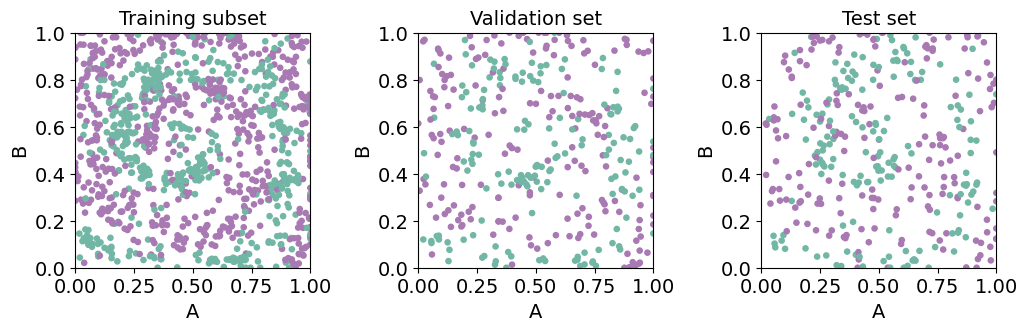

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))

for ax, X_part, y_part, title in zip(
    axes,
    [X_train_subset, X_val, X_test],
    [y_train_subset, y_val, y_test],
    ["Training subset", "Validation set", "Test set"],
):
    ax.scatter(
        X_part[:, 0],
        X_part[:, 1],
        c=[class_colors[label] for label in y_part],
        s=14,
    )
    ax.set_title(title)
    ax.set_xlabel("A")
    ax.set_ylabel("B")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

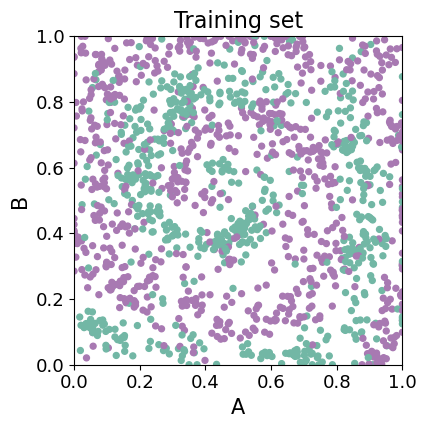

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))

ax.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=[class_colors[label] for label in y_train],
    s=18,
)

ax.set_title("Training set", fontsize=16)
ax.set_xlabel("A", fontsize=15)
ax.set_ylabel("B", fontsize=15)

ax.tick_params(axis="both", labelsize=13)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.savefig("spiral-training-set.pdf", bbox_inches="tight")
plt.show()


## Decision boundary
We have so far described a decision tree as repeatedly splitting the data into subsets. We can also view these splits geometrically. Each example is a point in feature space: in our case, with two features $A$ and $B$, this space is two-dimensional. A split such as $A < 0.4$ divides this space with a vertical line, while a split such as $B < 0.7$ divides it with a horizontal line. Repeated splits therefore divide the feature space into rectangular regions. Each terminal region corresponds to a leaf of the tree and is assigned one predicted class.

The borders between regions assigned to different classes form the **decision boundary** of the classifier. For a decision tree, this boundary consists of horizontal and vertical line segments.

With more features, the feature space has more dimensions. These higher-dimensional spaces are difficult to visualize, but the same geometric idea applies: each split divides the feature space into regions, and the decision boundary separates regions with different predicted classes.

## Model complexity
max_leaf_nodes limits how many terminal regions a tree can create. A small value forces a simple model with only a few regions; a large value allows the tree to divide the feature space more finely and create a more detailed decision boundary.

**Predict.** How should the predicted regions change as the number of leaves increases?

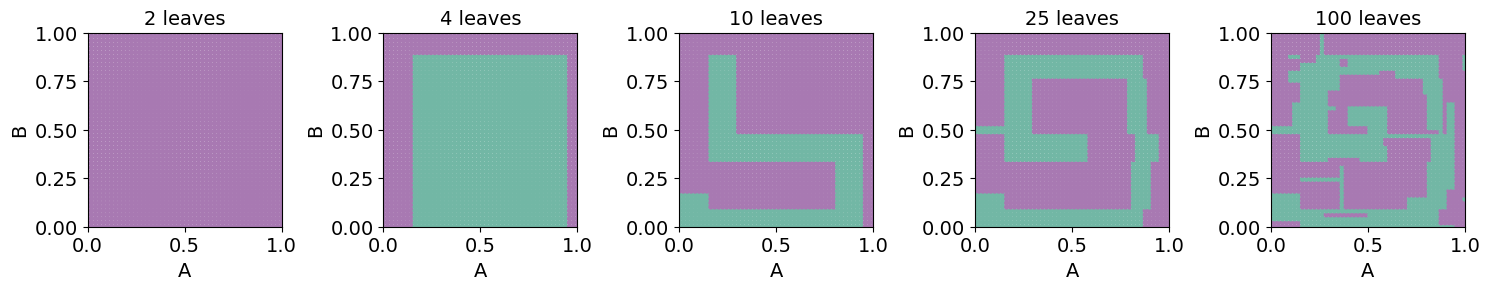

In [11]:
leaf_counts = [2, 4, 10, 25, 100]
fig, axes = plt.subplots(1, len(leaf_counts), figsize=(15, 3))

for ax, nodes in zip(axes, leaf_counts):
    model = tree.DecisionTreeClassifier(
        max_leaf_nodes=nodes,
        random_state=42,
    )
    model.fit(X_train_subset, y_train_subset)
    pred = model.predict(X_application)

    ax.scatter(
        X_application[:, 0], X_application[:, 1],
        c=[class_colors[label] for label in pred],
        s=8,
    )

    ax.set_title(f"{nodes} leaves")
    ax.set_xlabel("A")
    ax.set_ylabel("B")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

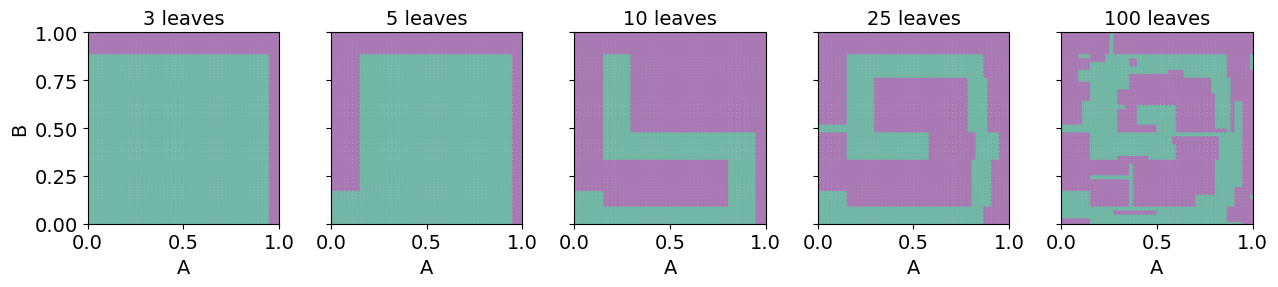

In [19]:
leaf_counts = [3, 5, 10, 25, 100]

fig, axes = plt.subplots(
    1, len(leaf_counts),
    figsize=(13, 2.8),
)

for i, (ax, nodes) in enumerate(zip(axes, leaf_counts)):
    model = tree.DecisionTreeClassifier(
        max_leaf_nodes=nodes,
        random_state=42,
    )
    model.fit(X_train_subset, y_train_subset)
    pred = model.predict(X_application)

    ax.scatter(
        X_application[:, 0],
        X_application[:, 1],
        c=[class_colors[label] for label in pred],
        s=8,
    )

    ax.set_title(f"{nodes} leaves")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal", adjustable="box")

    # Keep axis labels only where they add information.
    ax.set_xlabel("A")
    if i == 0:
        ax.set_ylabel("B")
    else:
        ax.set_yticklabels([])

plt.tight_layout()
plt.savefig(
    "spiral-tree-complexity.pdf",
    bbox_inches="tight",
)
plt.show()

InvalidParameterError: The 'max_leaf_nodes' parameter of DecisionTreeClassifier must be an int in the range [2, inf) or None. Got 1 instead.

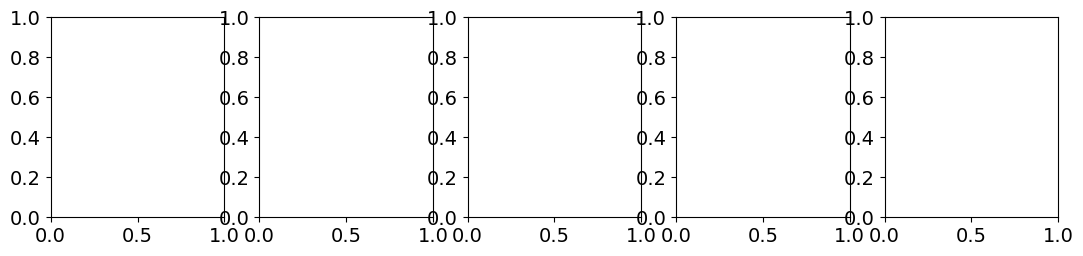

In [18]:
leaf_counts = [1, 4, 10, 25, 100]

fig, axes = plt.subplots(
    1, len(leaf_counts),
    figsize=(13, 2.6),
)

for ax, nodes in zip(axes, leaf_counts):
    model = tree.DecisionTreeClassifier(
        max_leaf_nodes=nodes,
        random_state=42,
    )
    model.fit(X_train_subset, y_train_subset)
    pred = model.predict(X_application)

    ax.scatter(
        X_application[:, 0],
        X_application[:, 1],
        c=[class_colors[label] for label in pred],
        s=8,
    )

    ax.set_title(f"{nodes} leaves")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig(
    "spiral-tree-complexity.pdf",
    bbox_inches="tight",
)


plt.tight_layout()

plt.savefig(
    "spiral-tree-complexity.pdf",
    bbox_inches="tight",
)

plt.show()

A very small tree **underfits**: it cannot represent enough of the spiral. As the tree grows, it captures more useful structure. With many leaves, however, the boundary becomes increasingly intricate and can begin to accommodate individual noisy observations.

**Takeaway.** More model complexity is useful only while it helps capture structure that generalizes.

## Training performance is not enough

We now fit trees with different values of `max_leaf_nodes`. For each tree we measure:

- **training accuracy** on the same training subset used to fit it;
- **validation accuracy** on examples that were not used to fit it.

**Predict.** Which curve should continue to improve most reliably as the tree becomes more complex?

In [7]:
max_nodes = list(range(2, 101))
accuracy_train = []
accuracy_val = []

for nodes in max_nodes:
    model = tree.DecisionTreeClassifier(
        max_leaf_nodes=nodes,
        random_state=42,
    )
    model.fit(X_train_subset, y_train_subset)

    accuracy_train.append(
        metrics.accuracy_score(
            y_train_subset, model.predict(X_train_subset)
        )
    )
    accuracy_val.append(
        metrics.accuracy_score(
            y_val, model.predict(X_val)
        )
    )

best_index = int(np.argmax(accuracy_val))
best_nodes = max_nodes[best_index]

print("Highest validation accuracy:")
print("  max_leaf_nodes =", best_nodes)
print("  accuracy       =", round(accuracy_val[best_index], 3))

Highest validation accuracy:
  max_leaf_nodes = 45
  accuracy       = 0.832


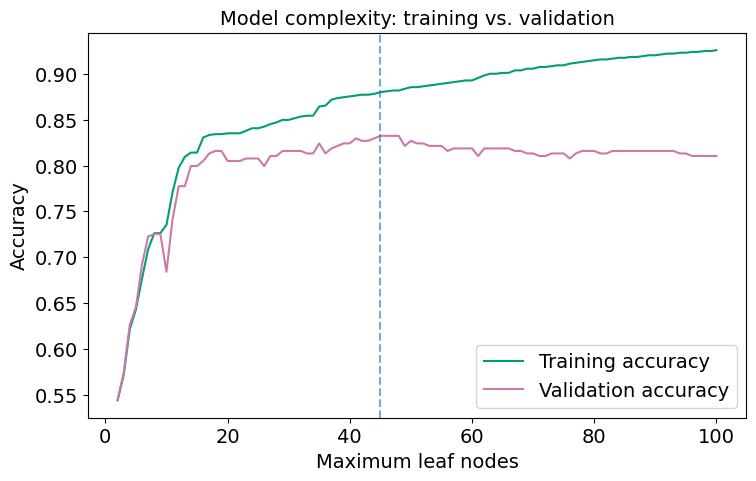

In [8]:
plt.figure(figsize=(8.5, 5))
plt.plot(
    max_nodes, accuracy_train,
    label="Training accuracy",
    color=TRAIN_COLOR,
)
plt.plot(
    max_nodes, accuracy_val,
    label="Validation accuracy",
    color=VALIDATION_COLOR,
)
plt.axvline(best_nodes, linestyle="--", alpha=0.6)

plt.xlabel("Maximum leaf nodes")
plt.ylabel("Accuracy")
plt.title("Model complexity: training vs. validation")
plt.legend()
plt.show()

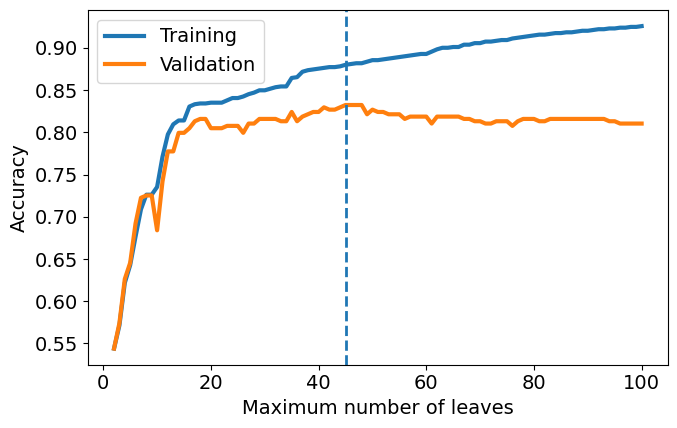

In [20]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    max_nodes,
    accuracy_train,
    label="Training",
    linewidth=3,
)

ax.plot(
    max_nodes,
    accuracy_val,
    label="Validation",
    linewidth=3,
)

ax.set_xlabel("Maximum number of leaves")
ax.set_ylabel("Accuracy")
ax.legend()

plt.tight_layout()
plt.savefig(
    "spiral-training-validation.pdf",
    bbox_inches="tight",
)

ax.axvline(
    best_nodes,
    linestyle="--",
    linewidth=2,
)
plt.tight_layout()

plt.savefig(
    "spiral-training-validation.pdf",
    bbox_inches="tight",
)

plt.show()

Training accuracy keeps increasing because a larger tree can fit more details of the training subset, including some of the deliberately corrupted labels. Validation accuracy improves much less and eventually fluctuates or deteriorates.

This growing difference between training and validation performance is evidence of **overfitting**.

**Think.** The highest observed validation accuracy may occur for a fairly large tree. Would you necessarily regard that exact tree as clearly better than a much smaller tree with almost the same validation accuracy?

<details>
<summary><strong>Answer</strong></summary>

No. Validation accuracy is itself an estimate based on a finite sample. Small differences may reflect which examples happened to enter the validation set rather than a real difference in generalization.

</details>

**Takeaway.** Do not interpret tiny differences in validation performance as exact measurements of future performance.

## Hyperparameters and model selection

`max_leaf_nodes` is a **hyperparameter**: we choose its value, and it controls how the learning algorithm builds the model.

The split variables, split thresholds, and leaf predictions of a particular tree are **parameters** learned from the training data.

Comparing candidate hyperparameter values using validation data is called **hyperparameter tuning** or **model selection**.

The procedure is:

1. fit candidate models on the training subset;
2. compare them using the validation set;
3. choose the hyperparameter;
4. refit the selected model using the complete training set;
5. evaluate it once on the untouched test set.

**Important.** Any data-dependent preprocessing—such as scaling, imputation, feature selection, or PCA—must be learned from the training data only. In practice, preprocessing steps and the model should therefore be combined in a pipeline, so that the same train/validation/test separation applies to the entire learning procedure, not just to the final model.

In [9]:
selected_tree = tree.DecisionTreeClassifier(
    max_leaf_nodes=best_nodes,
    random_state=42,
)

# Model selection is finished, so use the complete training set.
selected_tree.fit(X_train, y_train)

test_accuracy = metrics.accuracy_score(
    y_test, selected_tree.predict(X_test)
)

print("Selected max_leaf_nodes:", best_nodes)
print("Final test accuracy:", round(test_accuracy, 3))

Selected max_leaf_nodes: 45
Final test accuracy: 0.772


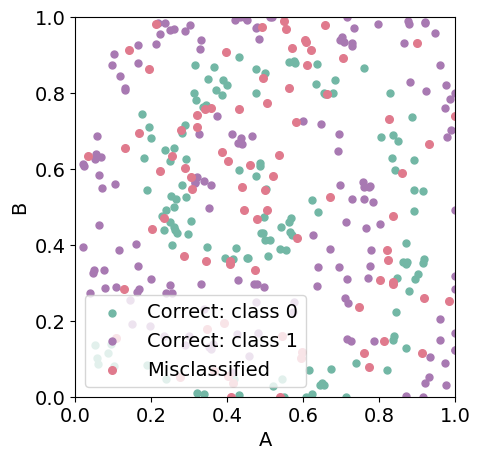

In [10]:
# Predict the untouched test set.
y_pred = selected_tree.predict(X_test)


correct_0 = (y_test == 0) & (y_pred == 0)
correct_1 = (y_test == 1) & (y_pred == 1)
incorrect = y_test != y_pred

plt.figure(figsize=(5, 5))

plt.scatter(
    X_test[correct_0, 0],
    X_test[correct_0, 1],
    color=CLASS_0_COLOR,
    s=25,
    label="Correct: class 0",
)

plt.scatter(
    X_test[correct_1, 0],
    X_test[correct_1, 1],
    color=CLASS_1_COLOR,
    s=25,
    label="Correct: class 1",
)

plt.scatter(
    X_test[incorrect, 0],
    X_test[incorrect, 1],
    color=ERROR_COLOR,
    s=30,
    label="Misclassified",
)

plt.xlabel("A")
plt.ylabel("B")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.tight_layout()
plt.show()

**Check.** Why should we not now try several other values of `max_leaf_nodes` and keep whichever performs best on the test set?

<details>
<summary><strong>Answer</strong></summary>

Because the test set would then become part of model selection. Its score would no longer be an independent evaluation of the completed procedure.

</details>

## From a validation set to cross-validation

There is still a problem: **why should one particular validation set decide?**

The validation examples are themselves only a sample. If we made a different random split, the validation curve could change and we might choose a different value of `max_leaf_nodes`.

Instead of permanently assigning one part of the training set to validation, we can let different parts take turns playing the validation role.

For example, in 5-fold cross-validation:

```text
Fold 1:  VALIDATE | train    | train    | train    | train
Fold 2:  train    | VALIDATE | train    | train    | train
Fold 3:  train    | train    | VALIDATE | train    | train
Fold 4:  train    | train    | train    | VALIDATE | train
Fold 5:  train    | train    | train    | train    | VALIDATE
```

Each candidate hyperparameter is evaluated several times, and the validation scores are combined.

The **test set still remains untouched**.

**Think.** What problem does cross-validation address that a single validation set does not?

<details>
<summary><strong>Answer</strong></summary>

It makes model selection less dependent on one particular random validation split. Each training example can take part in validation while the test set remains independent.

</details>

**Takeaway.** We use validation data because training performance cannot tell us how well a model generalizes. Cross-validation makes this estimate less dependent on one particular split.

**Important.** If model development includes data-dependent preprocessing, such as scaling, imputation, feature selection, or PCA, these steps can interact with the model and its hyperparameters and must therefore be evaluated together. They must also be learned from the training data only. In practice, we combine preprocessing and the model in a pipeline. We will see how scikit-learn supports pipelines and hyperparameter tuning in a separate notebook.

## Explore and apply

1. **Change the noise.** Try `noise = 0`, `0.05`, `0.10`, `0.20`, and `0.30`. How do the decision regions and the training/validation curves change? At what point does overfitting become particularly visible?
2. **Change the split.** Change the random seed used for the training/validation split. Does the same value of `max_leaf_nodes` still look best?
3. **Change the amount of training data.** Repeat the experiment with fewer or more examples. How does sample size affect the gap between training and validation performance?
4. **Compare models visually.** Compare the decision regions of a relatively simple tree with those of the tree having the highest validation accuracy. Is the more complex boundary obviously preferable?
5. **Explain the test set.** In your own words, explain why looking repeatedly at test accuracy while choosing `max_leaf_nodes` would turn the test set into part of model development.